# Method (b): Grounded Heuristic Injection — Live Demo

This notebook runs the actual functions from `generate_synthetic.py` / `solutions/common/synth_common.py` (no copies, no reimplementation) against real records from `data/train.jsonl`, and shows the before/after result for each of the 5 hallucination classes.

**What "grounded" means here**, as opposed to the ungrounded dictionary-swap approach in the old `last_experiment/S1a`: each injector corrupts a *clean* response using signal that is actually present — either in the paired image (OCR) or already inside the response's own text (a number, a color word) — rather than inserting arbitrary unrelated content. `invention` is the one exception (fabricated content is by definition absent from the image, so there's nothing to ground it in).

| label | function | grounded in |
|---|---|---|
| OCR | `make_ocr_injection` | text EasyOCR actually detects in the paired image |
| miscounting | `make_miscounting_injection` | a number (digit or spelled-out word) already in the response |
| mischaracterization | `make_mischaracterization_injection` | a color/size/material/texture word already in the response |
| other | `make_other_injection` | a state/direction word already in the response, or a repetition-loop pattern |
| invention | `make_invention_injection` | not grounded — templated addition, positioned at a random real sentence boundary |

Every design choice below (which characters to swap, digit vs. word-number, which languages fire, where to insert) was tuned by measuring real gold spans in `data/train.jsonl` and comparing — see `README.md`'s "(b) Grounded heuristic injection" section for the full quantified before/after for each fix. This notebook is the "show me" companion to that writeup.

In [1]:
import html as html_lib
import random
import sys
from pathlib import Path

from IPython.display import display, HTML
from PIL import Image

_THIS_DIR = Path.cwd()
_REPO_ROOT = _THIS_DIR.parent.parent
for p in (_REPO_ROOT, _THIS_DIR):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from solutions.common import data_io
from solutions.common import synth_common as sc
import ocr_extract
import generate_synthetic as gs

print("repo root:", _REPO_ROOT)

repo root: C:\Users\ROG\Desktop\Shroom-visions Shared Task


In [2]:
records = data_io.load_jsonl(data_io.TRAIN_FILE)
clean_seeds = [r for r in records if not r.get("labels")]
random.Random(0).shuffle(clean_seeds)
print(f"{len(records)} total train records, {len(clean_seeds)} clean (label-free) seeds available to corrupt")

from collections import Counter
print("clean seeds by language:", Counter(r["language"] for r in clean_seeds))

12082 total train records, 3436 clean (label-free) seeds available to corrupt
clean seeds by language: Counter({'zh': 1091, 'en': 801, 'it': 774, 'fr': 770})


In [3]:
def show_image(image_name, max_width=280):
    path = data_io.resolve_image_path(image_name, data_io.IMAGE_DIR)
    if path is None:
        print(f"  (image not found on disk: {image_name})")
        return
    img = Image.open(path).convert("RGB")
    img.thumbnail((max_width, max_width))
    display(img)


def show_injection(seed_record, synthetic_record, note=""):
    """Renders original vs. corrupted response, with the injected span
    highlighted, plus the label/tag/language metadata."""
    lb = synthetic_record["labels"][0]
    label, start, end = lb["label"], lb["start"], lb["end"]
    tag = synthetic_record["id"].split("_", 2)[1]
    resp = synthetic_record["response"]
    highlighted = (
        html_lib.escape(resp[:start])
        + '<mark style="background:#ffe08a">' + html_lib.escape(resp[start:end]) + '</mark>'
        + html_lib.escape(resp[end:])
    )
    display(HTML(f"""
    <div style="border:1px solid #ccc;border-radius:6px;padding:10px;margin:6px 0 14px 0;font-family:sans-serif;max-width:820px">
      <div><b>label:</b> {label} &nbsp; <b>injector tag:</b> {tag} &nbsp; <b>language:</b> {synthetic_record.get('language')} &nbsp; {note}</div>
      <div style="margin-top:8px;color:#555"><b>original (clean) response:</b><br>{html_lib.escape(seed_record['response'])}</div>
      <div style="margin-top:8px"><b>synthetic response &mdash; injected span highlighted:</b><br>{highlighted}</div>
    </div>
    """))


def scan_by_language(injector, seeds, n_per_lang=1, languages=("en", "fr", "it", "zh"), max_scan=4000):
    """Scans clean seeds and returns up to n_per_lang successful injections
    per language. Most injectors need specific content to fire (a number, a
    color word, ...), so most seeds are skipped -- this just keeps scanning
    until each language has an example or max_scan is exhausted."""
    found = {lang: [] for lang in languages}
    for rec in seeds[:max_scan]:
        lang = rec.get("language")
        if lang not in found or len(found[lang]) >= n_per_lang:
            continue
        synth = injector(rec)
        if synth is not None:
            found[lang].append((rec, synth))
        if all(len(v) >= n_per_lang for v in found.values()):
            break
    return found


def scan_by_tag(injector, seeds, tags, n_each=1, max_scan=4000):
    """Like scan_by_language, but buckets by the injector's own tag instead
    of language -- used for `other`, which draws from two contributors."""
    found = {t: [] for t in tags}
    for rec in seeds[:max_scan]:
        synth = injector(rec)
        if synth is None:
            continue
        tag = synth["id"].split("_", 2)[1]
        if tag in found and len(found[tag]) < n_each:
            found[tag].append((rec, synth))
        if all(len(v) >= n_each for v in found.values()):
            break
    return found

## 1. OCR — `make_ocr_injection`

Runs EasyOCR over the paired image, takes text it actually detected, and applies `confusable_swap` (rn&harr;m, cl&harr;d, I/l preferred, O&harr;0/S&harr;5 as a low-probability fallback) to turn it into a plausible misreading. The corrupted string is appended as a new sentence (`"The text visible in the image reads '...'"`), so the injected span is exactly the corrupted OCR string.

This cell runs a **real EasyOCR pass** over a small sample of images (mirrors the `--smoke_test` 15-image cap in `run_pipeline.py` — the full ~2,054-image pass takes hours, not appropriate for a demo notebook). CPU-only (`gpu=False`) for portability; nothing is written to `ocr_cache.json`, this is a self-contained scratch run.

In [4]:
sample_pool = clean_seeds[:60]
sample_images = sorted({r["image_name"] for r in sample_pool})[:15]
print(f"Running EasyOCR over {len(sample_images)} sample images (CPU, no cache write)...")
demo_ocr_cache = ocr_extract.extract_ocr_cache(sample_images, gpu=False)
print(f"{len(demo_ocr_cache)}/{len(sample_images)} images had detectable text")

Running EasyOCR over 15 sample images (CPU, no cache write)...


Using CPU. Note: This module is much faster with a GPU.


Using CPU. Note: This module is much faster with a GPU.


EasyOCR:   0%|          | 0/15 [00:00<?, ?img/s]

4/15 images had detectable text


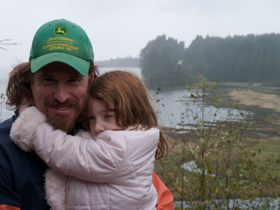

EasyOCR detected in this image: ['DEERE', 'JOHN', 'POWER', 'CLATSOP ', 'EQUIP', 'ASTORIA', 'CLASOP', 'OR']


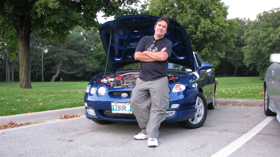

EasyOCR detected in this image: ['ITIBUR', 'TIBUR']


In [5]:
rng = random.Random(7)
shown = 0
for rec in sample_pool:
    if rec["image_name"] not in demo_ocr_cache:
        continue
    synth = gs.make_ocr_injection(rec, demo_ocr_cache, rng)
    if synth is None:
        continue
    show_image(rec["image_name"])
    print("EasyOCR detected in this image:", demo_ocr_cache[rec["image_name"]])
    show_injection(rec, synth)
    shown += 1
    if shown >= 4:
        break
if shown == 0:
    print("No OCR injection fired on this sample -- EasyOCR found no confusable-eligible text "
          "in these particular 15 images. Re-run the previous cell with a larger sample_pool slice.")

## 2. Miscounting — `make_miscounting_injection`

Shifts a number already mentioned in the response by a small offset (&plusmn;1 most likely, &plusmn;2 less likely). Tries the **spelled-out word form first** (`shift_number_word`, e.g. "two"&rarr;"three", "trois"&rarr;"quatre", "四"&rarr;"三") and only falls back to digit-shifting (`shift_number`) if no number word is found — real gold miscounting spans are 79% spelled-out words, only 21% digits, so word-form is the majority case, not the fallback.

In [6]:
rng = random.Random(11)
miscounting_found = scan_by_language(lambda r: gs.make_miscounting_injection(r, rng), clean_seeds)
for lang, pairs in miscounting_found.items():
    for seed, synth in pairs:
        tag = synth["id"].split("_", 2)[1]
        show_injection(seed, synth, note=f"(word-form example, tag={tag})" if tag == "cntword" else f"(digit-fallback example, tag={tag})")

## 3. Mischaracterization — `make_mischaracterization_injection`

Swaps a color/size/material/texture word already in the response for a plausible antonym (`swap_visual_attribute`), using a **per-language** dictionary (en/fr/it/zh) — an earlier English-only version barely ever fired on fr/it/zh responses (3-6% vs. 14.8% for English).

In [7]:
rng = random.Random(22)
mischar_found = scan_by_language(lambda r: gs.make_mischaracterization_injection(r, rng), clean_seeds)
for lang, pairs in mischar_found.items():
    for seed, synth in pairs:
        show_injection(seed, synth)

## 4. Other — `make_other_injection`

Two contributors, weighted 75/25 toward the better-understood one, because this is the weakest-grounded class of the five (real gold `other` spans are a heterogeneous mix with no single dominant structural signature):

- **`stateswap`** (75%): swaps a state/direction/relation word (open&harr;closed, left&harr;right, ...) for its antonym — `swap_state_word`, same per-language-dictionary fix as mischaracterization above, kept as a *separate* dictionary since state/direction errors map to "other" rather than mischaracterization per `docs/2026.md`'s own category definitions.
- **`reployop`** (25%): injects a repetition-loop (a short chunk repeated 6-40 times) — `inject_repetition_loop`, grounded in a measured (not assumed) ~4% real pattern of this exact generation-degeneration artifact in gold `other` spans.

Both are shown below, scanning until at least 2 of each tag are found:

In [8]:
rng = random.Random(33)
other_found = scan_by_tag(lambda r: gs.make_other_injection(r, rng), clean_seeds, tags=["stateswap", "reployop"], n_each=2)
for tag, pairs in other_found.items():
    for seed, synth in pairs:
        show_injection(seed, synth)

## 5. Invention — `make_invention_injection`

The one class with **no real signal to ground by definition** — fabricated content is, by definition, absent from the image. Inserts a short per-language templated addendum (localized object noun, not a single English list reused across languages) at a **randomly chosen real sentence boundary** rather than always at the very end — real gold invention spans are roughly uniform across the response (37/35/28% early/mid/late), not clustered at the end (only 14% land there).

In [9]:
rng = random.Random(44)
invention_found = scan_by_language(lambda r: gs.make_invention_injection(r, rng), clean_seeds)
for lang, pairs in invention_found.items():
    for seed, synth in pairs:
        show_injection(seed, synth)

## 6. Putting it together — `generate_heuristic_injections` at small scale

This is the actual function `generate_synthetic.py` calls in the real pipeline: for each label, it targets `base_per_label &times; rarity_multiplier` examples (rarity multipliers computed from the real full `data/train.jsonl` class counts — rarer classes like OCR/other get a bigger target), and stops early per label once real groundable signal runs out. Running it here with a small `base_per_label` and the tiny 15-image demo OCR cache from section 1 above (not the full ~2,054-image cache) makes the OCR-class throughput ceiling visible directly — a small, real illustration of the "throughput is naturally bounded by how much real signal exists" design note in `generate_synthetic.py`'s docstring.

In [10]:
rarity_multipliers = sc.compute_rarity_multipliers(records)
print("rarity multipliers (from the real full train set):", rarity_multipliers)

demo_synth = gs.generate_heuristic_injections(
    records, demo_ocr_cache, rarity_multipliers, base_per_label=5, seed=42,
)

rarity multipliers (from the real full train set): {'invention': 1, 'mischaracterization': 1, 'OCR': 7, 'miscounting': 4, 'other': 5}
  heuristic injection <invention>: 5/5 generated
  heuristic injection <mischaracterization>: 5/5 generated
  heuristic injection <OCR>: 15/35 generated
  heuristic injection <miscounting>: 20/20 generated
  heuristic injection <other>: 25/25 generated


In [11]:
import pandas as pd

df = pd.DataFrame([
    {
        "label": r["labels"][0]["label"],
        "tag": r["id"].split("_", 2)[1],
        "language": r["language"],
        "span_len": r["labels"][0]["end"] - r["labels"][0]["start"],
        "response_preview": (r["response"][:70] + "...") if len(r["response"]) > 70 else r["response"],
    }
    for r in demo_synth
])
df

,label,tag,language,span_len,response_preview
0,invention,objadd,zh,14,There is one cat in the image.附近似乎还有一辆红色自行车。
1,invention,objadd,it,57,"Nell immagine, una persona porta gli occhiali...."
2,invention,objadd,it,48,Il braccialetto alla caviglia del personaggio ...
3,invention,objadd,en,52,There also appears to be a small a trash can n...
4,invention,objadd,it,55,Non posso determinare se il motore del camion ...
...,...,...,...,...,...
65,other,reployop,fr,350,"Non, cet alligator n'est pas de couleur foncée..."
66,other,reployop,it,260,"No, il leone in questa immagine ha il pelo bia..."
67,other,reployop,fr,69,Je ne peux pas déterminer l'année ou le moment...
68,other,stateswap,en,4,"Based on the image provided, there are two dis..."


## Notes

- This notebook only exercises method **(b) grounded heuristic injection**. Methods (a) rarity/certainty upsampling (pure duplication) and (c) optional LLM-assisted injection (gated on `ANTHROPIC_API_KEY`) are covered in `README.md` and `llm_inject.py` respectively, not here.
- The real full pipeline (`run_pipeline.py`) runs EasyOCR once over all ~2,054 unique training images and caches to `ocr_cache.json`; this notebook always regenerates a small throwaway cache in-memory so it stays fast and doesn't clobber that cache file.
- Every quantified before/after comparison against real gold spans referenced in the markdown above (character composition, word-vs-digit split, language-firing rate, sentence-position distribution) was measured directly from `data/train.jsonl` during development — see `README.md`'s "(b) Grounded heuristic injection" section for the full numbers and the fixes each measurement drove.